# Method 2: XGBoost Regressor

**Owner:** Natiq Ghafoor

Predict each driver's finishing position from pre-race features, then rank the predictions within each race to get a valid finishing order.

The data setup is identical in both method notebooks so the comparison is fair. Sections 6 and 7 tune XGBoost on 2024, report 2025 test results over five seeds, compare with the grid baseline, and run the error analysis and the feature-group ablation.

### 0. Running on Colab or Kaggle (skip when running locally)
Locally, open this notebook from the `notebooks/` folder after `pip install -r requirements.txt`. On Colab or Kaggle (internet on), this cell clones the repo so `f1_utils` and the data are available.

In [13]:
import os, sys
try:
    import f1_utils  # noqa: F401  (already in notebooks/)
except ImportError:
    if not os.path.exists("f1-race-prediction"):
        os.system("git clone https://github.com/heavydriver/f1-race-prediction.git")
    os.chdir("f1-race-prediction/notebooks")
    sys.path.insert(0, os.getcwd())
print("working dir:", os.getcwd())

Cloning into 'f1-race-prediction'...


working dir: /kaggle/working/f1-race-prediction/notebooks


## 1. Setup

### 1.1 Imports

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import ParameterGrid
from xgboost import XGBRegressor

import f1_utils as f1

### 1.2 Plot theme

In [15]:
f1.set_f1_theme()
NOTEBOOK = "method-02-natiq"  # figures are saved to figures/method-02-natiq/

### 1.3 Seeds

Final results are reported as mean and std over these five seeds (splits stay the same).

In [16]:
SEEDS = f1.SEEDS
SEEDS

[1, 7, 42, 99, 2026]

## 2. Data

### 2.1 Load CSV

In [17]:
df = f1.load_data()
print(df.shape)
df.head()

(5105, 53)


,row_id,raceId,year,round,date,race_name,driverId,driver_ref,constructorId,constructor_ref,...,circuit_safety_car_rate,circuit_safety_car_avg,circuit_red_flag_rate,race_time_of_day,air_temp,wind_speed,humidity,rain,finish_position,dnf
0,900_1,900,2014,1,2014-03-16,Australian Grand Prix,1,hamilton,131,mercedes,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,19,1
1,900_817,900,2014,1,2014-03-16,Australian Grand Prix,817,ricciardo,9,red_bull,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,22,1
2,900_3,900,2014,1,2014-03-16,Australian Grand Prix,3,rosberg,131,mercedes,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,1,0
3,900_825,900,2014,1,2014-03-16,Australian Grand Prix,825,kevin_magnussen,1,mclaren,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,2,0
4,900_4,900,2014,1,2014-03-16,Australian Grand Prix,4,alonso,6,ferrari,...,0.555556,1.055556,0.055556,day,19.6,18.7,42.0,0.0,4,0


### 2.2 Column groups

- **ID columns**: kept for ranking and analysis, **not** used as features
- **Label columns**: `finish_position` is the target; `dnf` is only for analysis
- **Categorical features**: one-hot encoded
- **Numeric features**: everything else (grid, qualifying, standings, history, circuit, weather)

In [18]:
ID_COLS = [
    "row_id", "raceId", "year", "date", "race_name", "driverId", "constructorId", "circuitId",
]
LABEL_COLS = ["finish_position", "dnf"]
CAT_COLS = ["circuit_type", "race_time_of_day", "driver_ref", "constructor_ref", "circuit_ref"]
NUM_COLS = [c for c in df.columns if c not in ID_COLS + LABEL_COLS + CAT_COLS]

FEATURE_COLS = NUM_COLS + CAT_COLS
TARGET = f1.TARGET

print(f"{len(NUM_COLS)} numeric features:", NUM_COLS)
print(f"{len(CAT_COLS)} categorical features:", CAT_COLS)

38 numeric features: ['round', 'grid', 'quali_position', 'last_quali_session', 'quali_gap_to_pole_s', 'teammate_quali_gap_s', 'grid_minus_quali', 'driver_champ_pos', 'driver_champ_points', 'driver_champ_wins', 'constructor_champ_pos', 'constructor_champ_points', 'constructor_champ_wins', 'constructor_avg_finish_l3', 'career_races', 'career_wins', 'career_podiums', 'career_avg_finish', 'career_dnf_rate', 'circuit_races', 'circuit_avg_finish', 'circuit_wins', 'circuit_podiums', 'races_with_constructor', 'stint_races_with_constructor', 'avg_finish_l3', 'season_dnf_rate', 'circuit_dnf_rate', 'driver_age_years', 'circuit_alt', 'circuit_position_gain_avg', 'circuit_safety_car_rate', 'circuit_safety_car_avg', 'circuit_red_flag_rate', 'air_temp', 'wind_speed', 'humidity', 'rain']
5 categorical features: ['circuit_type', 'race_time_of_day', 'driver_ref', 'constructor_ref', 'circuit_ref']


### 2.3 Missing values

Missing values are intentional (e.g. no circuit history on a first visit, no form at round 1). See `project-docs/features.md`. They are imputed in step 4, fit on train only.

In [19]:
missing = df[FEATURE_COLS].isna().sum()
missing[missing > 0].sort_values(ascending=False).to_frame("missing rows")

,missing rows
circuit_avg_finish,1045
circuit_dnf_rate,1045
avg_finish_l3,268
season_dnf_rate,268
constructor_avg_finish_l3,244
circuit_position_gain_avg,163
teammate_quali_gap_s,144
last_quali_session,73
quali_gap_to_pole_s,73
career_dnf_rate,41


## 3. Chronological splits

### 3.1 Train / validation / test

| Split | Years | Purpose |
|---|---|---|
| Train | 2014-2023 | Model fitting |
| Validation | 2024 | Hyperparameter tuning |
| Test | 2025 | Final evaluation only (do not tune on it) |

In [20]:
train, val, test = f1.split_by_year(df)

pd.DataFrame({
    name: {"years": f"{d.year.min()}-{d.year.max()}", "races": d.raceId.nunique(), "rows": len(d)}
    for name, d in {"train": train, "val": val, "test": test}.items()
}).T

,years,races,rows
train,2014-2023,204,4147
val,2024-2024,24,479
test,2025-2025,24,479


### 3.2 Features and target

In [21]:
X_train, y_train = train[FEATURE_COLS], train[TARGET]
X_val, y_val = val[FEATURE_COLS], val[TARGET]
X_test, y_test = test[FEATURE_COLS], test[TARGET]

print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)

train: (4147, 43)  val: (479, 43)  test: (479, 43)


## 4. Feature encoding

### 4.1 Encoding pipeline

- **Numeric**: median imputation, plus a 0/1 indicator column for every feature that had missing values in train (so the model can tell "no history" apart from a real value)
- **Categorical**: one-hot encoding (unseen categories in val/test are ignored)
- Fit on **train only**, then transform val and test to avoid leakage

In [22]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])
preprocess.set_output(transform="pandas")

X_train_enc = preprocess.fit_transform(X_train)
X_val_enc = preprocess.transform(X_val)
X_test_enc = preprocess.transform(X_test)
feature_names = preprocess.get_feature_names_out()

### 4.2 Check the encoded matrices

In [23]:
for name, X in {"train": X_train_enc, "val": X_val_enc, "test": X_test_enc}.items():
    print(f"{name:5s} shape={X.shape}  NaNs={int(X.isna().sum().sum())}")

X_train_enc.head()

train shape=(4147, 163)  NaNs=0
val   shape=(479, 163)  NaNs=0
test  shape=(479, 163)  NaNs=0


,num__round,num__grid,num__quali_position,num__last_quali_session,num__quali_gap_to_pole_s,num__teammate_quali_gap_s,num__grid_minus_quali,num__driver_champ_pos,num__driver_champ_points,num__driver_champ_wins,...,cat__circuit_ref_sepang,cat__circuit_ref_shanghai,cat__circuit_ref_silverstone,cat__circuit_ref_sochi,cat__circuit_ref_spa,cat__circuit_ref_suzuka,cat__circuit_ref_vegas,cat__circuit_ref_villeneuve,cat__circuit_ref_yas_marina,cat__circuit_ref_zandvoort
0,1.0,1.0,1.0,3.0,0.000,-0.364,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,2.0,2.0,3.0,0.317,-0.140,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,3.0,3.0,3.0,0.364,0.364,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,4.0,4.0,3.0,1.514,1.308,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,5.0,5.0,3.0,1.588,1.325,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 4.3 Note on XGBoost and missing values

XGBoost can handle `NaN` natively (it learns a default direction at each split), so imputation is optional for it. We keep the same encoding for both methods so the comparison is fair. To try native NaN handling, change the numeric step to `"passthrough"`.

## 5. Hyperparameters

### 5.1 Candidate grid

Tuned on the **2024 validation set**: learning rate, number of trees, maximum tree depth, subsample size, and regularization. Edit the values below as needed.

In [24]:
PARAM_GRID = {
    "learning_rate": [0.03, 0.1],        # step size per boosting round
    "n_estimators": [300, 800],          # number of boosting rounds (trees)
    "max_depth": [3, 5, 7],              # depth of each tree
    "subsample": [0.8, 1.0],             # share of rows sampled per tree
    "reg_alpha": [0, 1],                 # L1 regularization
    "reg_lambda": [1, 5],                # L2 regularization
}

print(len(ParameterGrid(PARAM_GRID)), "combinations")

96 combinations


### 5.2 Starting values

Reasonable defaults to get a first result before running the full search.

In [25]:
DEFAULT_PARAMS = {
    "learning_rate": 0.05,
    "n_estimators": 500,
    "max_depth": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0,
    "reg_lambda": 1,
}

## 6. Training

### 6.1 Helper: predictions to race ranks

The model predicts a continuous position. `rank_predictions` turns it into a valid finishing order 1..N within each race (same as the baseline).

In [26]:
def rank_predictions(split_df, raw_pred):
    out = split_df.copy()
    out["pred_score"] = raw_pred
    out["pred_position"] = f1.to_race_ranks(out, "pred_score")
    return out

### 6.2 Tune on the validation set (2024)
Every combination in `PARAM_GRID` is fit on 2014-2023 and scored on 2024. `colsample_bytree` is fixed at 0.8 so row and column sampling make the seeds matter. The best setting is the one with the lowest validation MAE. The test set is not touched here.

In [27]:
import time, platform, xgboost, sklearn

PARAM_GRID["colsample_bytree"] = [0.8]
grid = list(ParameterGrid(PARAM_GRID))
print(len(grid), "combinations")

def fit_xgb(params, X, y, seed):
    model = XGBRegressor(**params, random_state=seed, n_jobs=-1, tree_method="hist")
    t0 = time.time()
    model.fit(X, y)
    return model, time.time() - t0

tuning_results = []
for i, params in enumerate(grid, 1):
    model, _ = fit_xgb(params, X_train_enc, y_train, seed=42)
    val_pred = rank_predictions(val, model.predict(X_val_enc))
    tuning_results.append({**params, **f1.evaluate(val_pred, "pred_position")})
    if i % 12 == 0:
        print(f"{i}/{len(grid)} done")

tuning_df = pd.DataFrame(tuning_results).sort_values("mae").reset_index(drop=True)
tuning_df.head(10).round(3)

96 combinations
12/96 done
24/96 done
36/96 done
48/96 done
60/96 done
72/96 done
84/96 done
96/96 done


,colsample_bytree,learning_rate,max_depth,n_estimators,reg_alpha,reg_lambda,subsample,accuracy,mae,podium_recall,spearman
0,0.8,0.03,3,300,1,5,0.8,0.123,2.984,0.556,0.739
1,0.8,0.03,3,300,0,5,1.0,0.136,2.988,0.583,0.736
2,0.8,0.03,3,300,0,1,0.8,0.146,3.009,0.556,0.733
3,0.8,0.03,3,300,1,1,0.8,0.152,3.022,0.597,0.730
4,0.8,0.03,3,300,1,5,1.0,0.127,3.022,0.583,0.731
5,0.8,0.03,3,800,1,5,1.0,0.152,3.034,0.542,0.724
6,0.8,0.03,3,300,0,5,0.8,0.121,3.034,0.569,0.733
7,0.8,0.03,3,300,1,1,1.0,0.125,3.046,0.556,0.727
8,0.8,0.03,3,300,0,1,1.0,0.132,3.050,0.556,0.724
9,0.8,0.03,3,800,0,5,1.0,0.152,3.075,0.486,0.718


In [28]:
PARAM_KEYS = list(grid[0].keys())
BEST_PARAMS = tuning_df.loc[0, PARAM_KEYS].to_dict()
for k in ["n_estimators", "max_depth"]:
    BEST_PARAMS[k] = int(BEST_PARAMS[k])
print("BEST_PARAMS =", BEST_PARAMS)

BEST_PARAMS = {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}


### 6.3 Final runs over seeds
The best parameters are refit on 2014-2023 with each of the five seeds (same as the Random Forest notebook), then scored on 2024 and 2025.

In [29]:
seed_results = {"val": [], "test": []}
test_preds, train_times = [], []
for seed in SEEDS:
    model, secs = fit_xgb(BEST_PARAMS, X_train_enc, y_train, seed)
    val_pred = rank_predictions(val, model.predict(X_val_enc))
    test_pred = rank_predictions(test, model.predict(X_test_enc))
    seed_results["val"].append(f1.evaluate(val_pred, "pred_position"))
    seed_results["test"].append(f1.evaluate(test_pred, "pred_position"))
    test_preds.append(test_pred)
    train_times.append(secs)
    if seed == SEEDS[0]:
        model_first = model
print(f"training time per fit: {np.mean(train_times):.1f} s")

training time per fit: 0.6 s


## 7. Evaluation and analysis

### 7.1 Validation results (tuning)

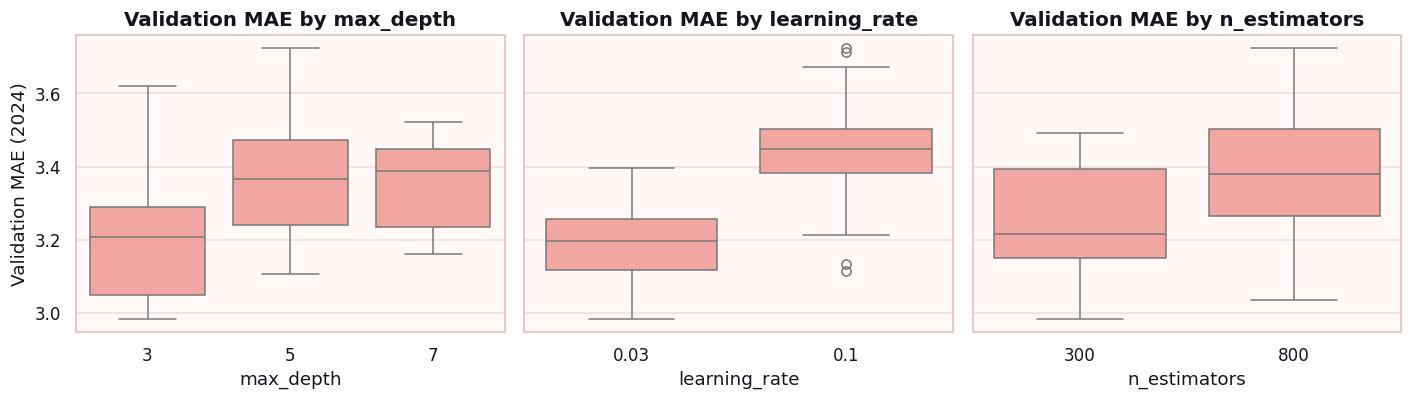

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, p in zip(axes, ["max_depth", "learning_rate", "n_estimators"]):
    sns.boxplot(data=tuning_df, x=p, y="mae", color="#FF9A94", ax=ax)
    ax.set(title=f"Validation MAE by {p}", xlabel=p, ylabel="Validation MAE (2024)")
fig.tight_layout()
f1.save_fig(fig, NOTEBOOK, "tuning_val_mae")
plt.show()

### 7.2 Test results (mean and std over seeds)

In [31]:
summary = pd.concat({name: f1.summarize_seeds(r) for name, r in seed_results.items()}, axis=1)
summary.round(3)

val          test       
                mean    std   mean    std
accuracy       0.125  0.006  0.157  0.014
mae            2.971  0.009  3.397  0.026
podium_recall  0.578  0.021  0.700  0.016
spearman       0.741  0.001  0.657  0.005

### 7.3 Comparison with the baseline
The baseline (finish where you start, pit-lane starts placed last) is recomputed here exactly as in `baseline.ipynb`, because `results/` is not committed to the repo.

In [32]:
PIT_LANE = 99

def predict_baseline(data):
    out = data.copy()
    out["start_pos"] = out["grid"].where(out["grid"] != 0, PIT_LANE)
    out["pred_position"] = f1.to_race_ranks(out, "start_pos")
    return out

base_val, base_test = predict_baseline(val), predict_baseline(test)
baseline = pd.DataFrame({"val": f1.evaluate(base_val, "pred_position"),
                         "test": f1.evaluate(base_test, "pred_position")}).T

def fmt(mean, std):
    return f"{mean:.3f} ± {std:.3f}"

METRICS = ["accuracy", "mae", "podium_recall", "spearman"]
xgb_test = pd.DataFrame(seed_results["test"])
comparison = pd.DataFrame({
    "Baseline (grid)": {m: fmt(baseline.loc["test", m], 0) for m in METRICS},
    "XGBoost": {m: fmt(xgb_test[m].mean(), xgb_test[m].std()) for m in METRICS},
}).T
comparison["train_time_s"] = ["0", f"{np.mean(train_times):.1f}"]
comparison

,accuracy,mae,podium_recall,spearman,train_time_s
Baseline (grid),0.184 ± 0.000,3.344 ± 0.000,0.750 ± 0.000,0.651 ± 0.000,0
XGBoost,0.157 ± 0.014,3.397 ± 0.026,0.700 ± 0.016,0.657 ± 0.005,0.6


XGBoost has lower MAE than the baseline in 10 of 24 races (tied in 1)


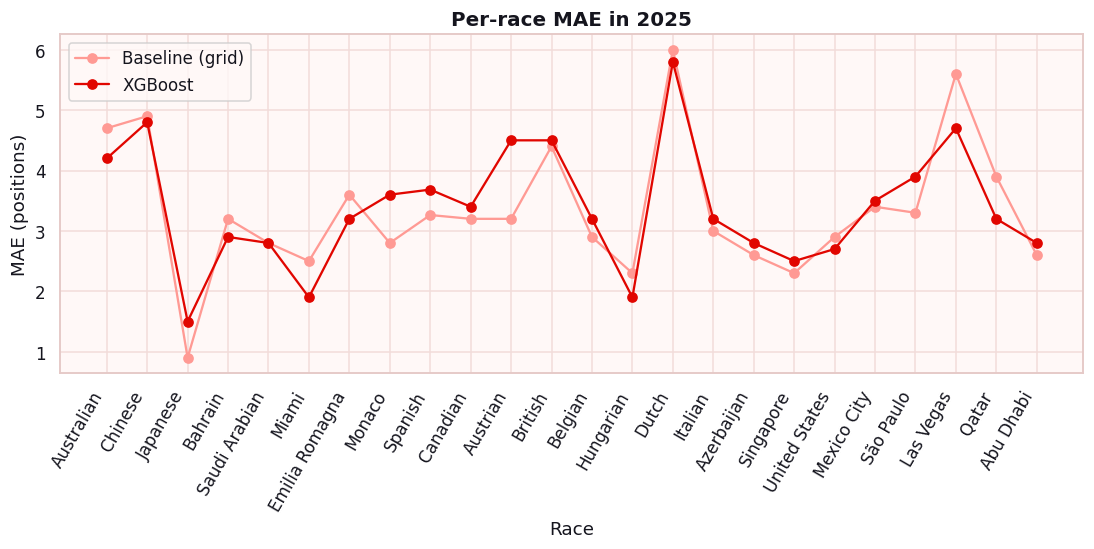

In [33]:
# Per race: in how many 2025 races does XGBoost (seed 1) beat the grid baseline?
xgb_races = f1.per_race_metrics(test_preds[0], "pred_position")
base_races = f1.per_race_metrics(base_test, "pred_position")
per_race = xgb_races[["round", "race_name", "mae", "spearman"]].merge(
    base_races[["round", "mae", "spearman"]], on="round", suffixes=("_xgb", "_base"))
per_race["mae_gain"] = per_race["mae_base"] - per_race["mae_xgb"]   # positive = XGBoost better
print(f"XGBoost has lower MAE than the baseline in {(per_race.mae_gain > 0).sum()} of {len(per_race)} races "
      f"(tied in {(per_race.mae_gain == 0).sum()})")

labels = per_race["race_name"].str.replace(" Grand Prix", "", regex=False)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(per_race["round"], per_race["mae_base"], marker="o", color="#FF9A94", label="Baseline (grid)")
ax.plot(per_race["round"], per_race["mae_xgb"], marker="o", color=f1.F1_RED, label="XGBoost")
ax.set_xticks(per_race["round"], labels, rotation=60, ha="right")
ax.set(title="Per-race MAE in 2025", xlabel="Race", ylabel="MAE (positions)")
ax.legend()
f1.save_fig(fig, NOTEBOOK, "per_race_mae_2025")
plt.show()

### 7.4 Feature importance
Gain importance from the seed-1 model. One-hot columns are summed back to their original feature (e.g. all `driver_ref_*` columns count as `driver_ref`).

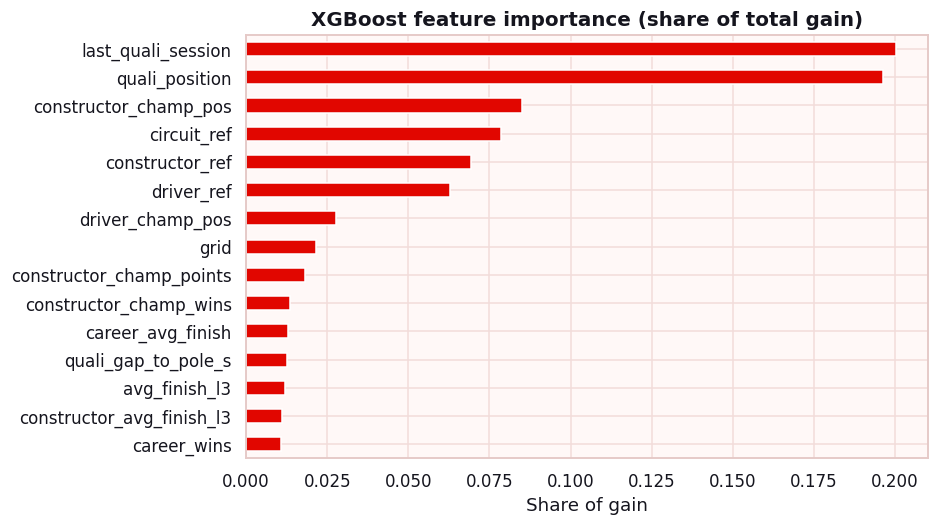

last_quali_session           0.200
quali_position               0.196
constructor_champ_pos        0.085
circuit_ref                  0.079
constructor_ref              0.069
driver_ref                   0.063
driver_champ_pos             0.028
grid                         0.022
constructor_champ_points     0.018
constructor_champ_wins       0.013
career_avg_finish            0.013
quali_gap_to_pole_s          0.012
avg_finish_l3                0.012
constructor_avg_finish_l3    0.011
career_wins                  0.011
dtype: float64

In [34]:
gain = pd.Series(model_first.get_booster().get_score(importance_type="gain"))
gain = gain.reindex(feature_names).fillna(0)

def base_feature(name):
    name = name.split("__", 1)[1]
    for c in CAT_COLS:
        if name.startswith(c + "_"):
            return c
    return name.replace("missingindicator_", "") + (" (missing)" if name.startswith("missingindicator_") else "")

importance = gain.groupby(gain.index.map(base_feature)).sum()
importance = (importance / importance.sum()).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importance.head(15)[::-1].plot.barh(color=f1.F1_RED, ax=ax)
ax.set(title="XGBoost feature importance (share of total gain)", xlabel="Share of gain", ylabel="")
f1.save_fig(fig, NOTEBOOK, "feature_importance")
plt.show()
importance.head(15).round(3)

### 7.5 Error analysis
Seed-1 predictions on 2025: error by starting position, finishers vs DNFs, worst races, and the biggest single misses.

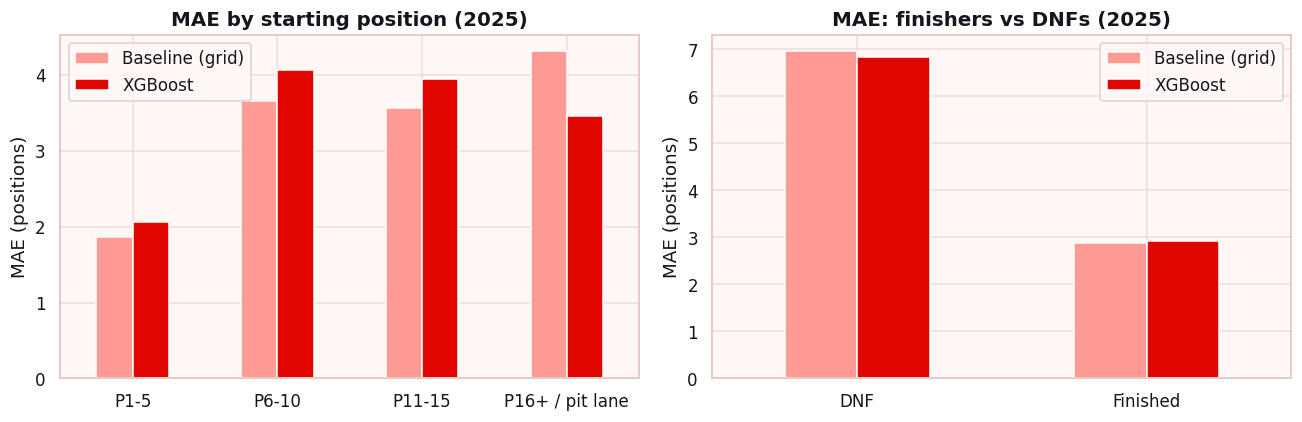

                 base_err  xgb_err
start_bucket                      
P1-5                1.858    2.058
P6-10               3.658    4.067
P11-15              3.558    3.942
P16+ / pit lane     4.311    3.462 

finishers only:
                  base_err  xgb_err
start_bucket                      
P1-5                1.379    1.612
P6-10               2.538    2.962
P11-15              3.102    3.755
P16+ / pit lane     4.632    3.594 

           base_err  xgb_err  rows
status                           
DNF          6.964    6.836    55
Finished     2.875    2.934   424


In [35]:
ea = test_preds[0][["round", "race_name", "driver_ref", "constructor_ref", "grid",
                    "finish_position", "dnf", "pred_position", "air_temp", "rain"]].copy()
ea["xgb_err"] = (ea["pred_position"] - ea["finish_position"]).abs()
ea["base_pred"] = base_test["pred_position"].values
ea["base_err"] = (ea["base_pred"] - ea["finish_position"]).abs()
ea["start_bucket"] = pd.cut(ea["grid"].replace(0, PIT_LANE), [0, 5, 10, 15, 100],
                            labels=["P1-5", "P6-10", "P11-15", "P16+ / pit lane"])
ea["status"] = ea["dnf"].map({0: "Finished", 1: "DNF"})

by_start = ea.groupby("start_bucket", observed=True)[["base_err", "xgb_err"]].mean()
by_status = ea.groupby("status")[["base_err", "xgb_err"]].mean()
by_status["rows"] = ea.groupby("status").size()
by_start_finishers = ea[ea.dnf == 0].groupby("start_bucket", observed=True)[["base_err", "xgb_err"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, table, title in [(axes[0], by_start, "MAE by starting position (2025)"),
                         (axes[1], by_status[["base_err", "xgb_err"]], "MAE: finishers vs DNFs (2025)")]:
    table.rename(columns={"base_err": "Baseline (grid)", "xgb_err": "XGBoost"}).plot.bar(
        color=["#FF9A94", f1.F1_RED], ax=ax, rot=0)
    ax.set(title=title, xlabel="", ylabel="MAE (positions)")
fig.tight_layout()
f1.save_fig(fig, NOTEBOOK, "error_breakdown")
plt.show()
print(by_start.round(3), "\n\nfinishers only:\n", by_start_finishers.round(3), "\n\n", by_status.round(3))

In [36]:
worst_races = per_race.sort_values("mae_xgb", ascending=False)
print("Worst 2025 races for XGBoost:")
print(worst_races.head(5)[["round", "race_name", "mae_xgb", "mae_base", "spearman_xgb"]].round(2).to_string(index=False))
print("\nBest 2025 races:")
print(worst_races.tail(3)[["round", "race_name", "mae_xgb", "mae_base", "spearman_xgb"]].round(2).to_string(index=False))

misses = ea.sort_values("xgb_err", ascending=False).head(12)[
    ["round", "race_name", "driver_ref", "grid", "pred_position", "finish_position", "status"]]
print("\nBiggest single misses:")
print(misses.to_string(index=False))

wet = ea.groupby(ea["rain"].map({0: "dry start", 1: "wet start"}))[["base_err", "xgb_err"]].mean()
wet["races"] = ea.groupby("rain")["round"].nunique().values
print("\nWet vs dry starts:\n", wet.round(3))

Worst 2025 races for XGBoost:
 round            race_name  mae_xgb  mae_base  spearman_xgb
    15     Dutch Grand Prix      5.8       6.0          0.09
     2   Chinese Grand Prix      4.8       4.9          0.41
    22 Las Vegas Grand Prix      4.7       5.6          0.37
    11  Austrian Grand Prix      4.5       3.2          0.51
    12   British Grand Prix      4.5       4.4          0.53

Best 2025 races:
 round            race_name  mae_xgb  mae_base  spearman_xgb
     6     Miami Grand Prix      1.9       2.5          0.91
    14 Hungarian Grand Prix      1.9       2.3          0.90
     3  Japanese Grand Prix      1.5       0.9          0.92

Biggest single misses:
 round             race_name driver_ref  grid  pred_position  finish_position   status
    22  Las Vegas Grand Prix     norris   1.0              2               19      DNF
    15      Dutch Grand Prix     norris   2.0              2               18 Finished
    17 Azerbaijan Grand Prix    piastri   9.0            

### 7.6 Ablation: remove one feature group at a time
Each run drops one group of features, refits the same encoding on train only, and retrains with `BEST_PARAMS` over all five seeds. The change in test MAE is paired by seed (positive = worse without that group).

The **weather** row checks the professor's leakage concern. Weather here is the Open-Meteo reading for the hour the race starts, which is known at lights out but not before the race weekend. If dropping it barely changes the results, the model is not relying on it.

In [37]:
FEATURE_GROUPS = {
    "Grid & qualifying": ["grid", "quali_position", "last_quali_session", "quali_gap_to_pole_s",
                          "teammate_quali_gap_s", "grid_minus_quali"],
    "Driver history & form": ["driver_champ_pos", "driver_champ_points", "driver_champ_wins",
                              "career_races", "career_wins", "career_podiums", "career_avg_finish",
                              "career_dnf_rate", "circuit_races", "circuit_avg_finish", "circuit_wins",
                              "circuit_podiums", "races_with_constructor", "stint_races_with_constructor",
                              "avg_finish_l3", "season_dnf_rate", "circuit_dnf_rate", "driver_age_years"],
    "Constructor form": ["constructor_champ_pos", "constructor_champ_points", "constructor_champ_wins",
                         "constructor_avg_finish_l3"],
    "Circuit & race setting": ["round", "circuit_type", "circuit_alt", "circuit_position_gain_avg",
                               "circuit_safety_car_rate", "circuit_safety_car_avg", "circuit_red_flag_rate",
                               "race_time_of_day"],
    "Weather": ["air_temp", "wind_speed", "humidity", "rain"],
    "Driver / team / circuit identity": ["driver_ref", "constructor_ref", "circuit_ref"],
}
grouped = [c for cols in FEATURE_GROUPS.values() for c in cols]
assert sorted(grouped) == sorted(FEATURE_COLS), set(FEATURE_COLS) ^ set(grouped)

def run_setting(features):
    num = [c for c in NUM_COLS if c in features]
    cat = [c for c in CAT_COLS if c in features]
    steps = []
    if num:
        steps.append(("num", SimpleImputer(strategy="median", add_indicator=True), num))
    if cat:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    pre = ColumnTransformer(steps).set_output(transform="pandas")
    Xtr = pre.fit_transform(train[features])
    Xte = pre.transform(test[features])
    rows = []
    for seed in SEEDS:
        model, _ = fit_xgb(BEST_PARAMS, Xtr, y_train, seed)
        rows.append({"seed": seed, **f1.evaluate(rank_predictions(test, model.predict(Xte)), "pred_position")})
    return pd.DataFrame(rows).set_index("seed")

full_runs = pd.DataFrame(seed_results["test"], index=SEEDS)
settings = {f"without {g}": [c for c in FEATURE_COLS if c not in cols] for g, cols in FEATURE_GROUPS.items()}
settings["only Grid & qualifying"] = FEATURE_GROUPS["Grid & qualifying"]

ablation_rows = [{"setting": "XGBoost (all features)",
                  **{m: fmt(full_runs[m].mean(), full_runs[m].std()) for m in METRICS}}]
ablation_deltas = []
for name, feats in settings.items():
    runs = run_setting(feats)
    row = {"setting": name, **{m: fmt(runs[m].mean(), runs[m].std()) for m in METRICS}}
    for m in METRICS:
        d = runs[m] - full_runs[m]
        row[f"Δ{m}"] = f"{d.mean():+.3f} ± {d.std():.3f}"
    ablation_rows.append(row)
    d = runs["mae"] - full_runs["mae"]
    ablation_deltas.append({"setting": name, "delta_mae": d.mean(), "std": d.std()})
    print("done:", name)

ablation = pd.DataFrame(ablation_rows).set_index("setting")
ablation

done: without Grid & qualifying
done: without Driver history & form
done: without Constructor form
done: without Circuit & race setting
done: without Weather
done: without Driver / team / circuit identity
done: only Grid & qualifying


,accuracy,mae,podium_recall,spearman,Δaccuracy,Δmae,Δpodium_recall,Δspearman
setting,,,,,,,,
XGBoost (all features),0.157 ± 0.014,3.397 ± 0.026,0.700 ± 0.016,0.657 ± 0.005,NaN,NaN,NaN,NaN
without Grid & qualifying,0.088 ± 0.010,4.203 ± 0.030,0.553 ± 0.018,0.544 ± 0.003,-0.069 ± 0.016,+0.806 ± 0.043,-0.147 ± 0.021,-0.112 ± 0.004
without Driver history & form,0.151 ± 0.011,3.425 ± 0.014,0.725 ± 0.015,0.648 ± 0.001,-0.006 ± 0.022,+0.028 ± 0.037,+0.025 ± 0.012,-0.009 ± 0.004
without Constructor form,0.161 ± 0.013,3.370 ± 0.039,0.694 ± 0.040,0.659 ± 0.004,+0.004 ± 0.021,-0.027 ± 0.026,-0.006 ± 0.038,+0.002 ± 0.002
without Circuit & race setting,0.165 ± 0.008,3.386 ± 0.022,0.703 ± 0.029,0.657 ± 0.003,+0.008 ± 0.016,-0.011 ± 0.027,+0.003 ± 0.025,-0.000 ± 0.005
without Weather,0.153 ± 0.007,3.382 ± 0.038,0.683 ± 0.027,0.659 ± 0.005,-0.004 ± 0.009,-0.016 ± 0.047,-0.017 ± 0.023,+0.002 ± 0.007
without Driver / team / circuit identity,0.148 ± 0.009,3.305 ± 0.031,0.711 ± 0.025,0.667 ± 0.003,-0.009 ± 0.019,-0.093 ± 0.036,+0.011 ± 0.027,+0.010 ± 0.005
only Grid & qualifying,0.162 ± 0.010,3.324 ± 0.022,0.747 ± 0.006,0.659 ± 0.003,+0.005 ± 0.011,-0.073 ± 0.034,+0.047 ± 0.012,+0.003 ± 0.006


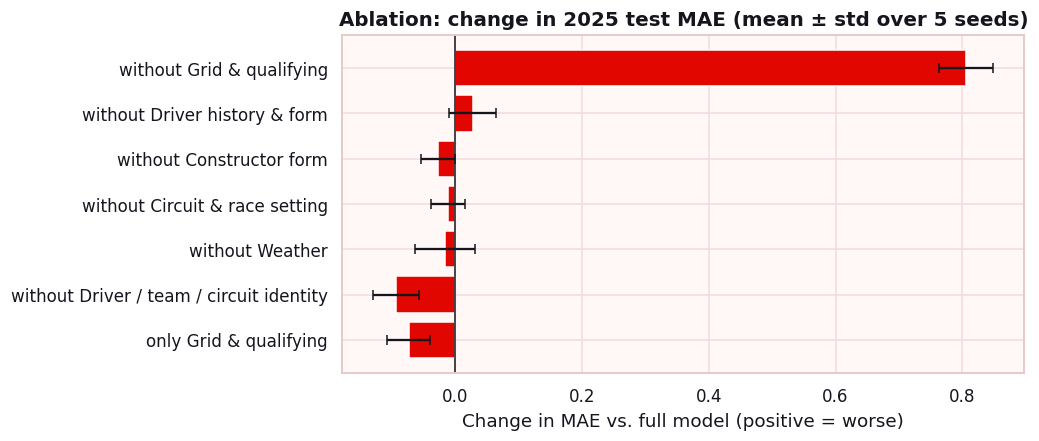

In [38]:
deltas = pd.DataFrame(ablation_deltas)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(deltas["setting"], deltas["delta_mae"], xerr=deltas["std"], color=f1.F1_RED,
        error_kw={"ecolor": f1.F1_CARBON, "capsize": 3})
ax.axvline(0, color=f1.F1_CARBON, lw=1)
ax.invert_yaxis()
ax.set(title="Ablation: change in 2025 test MAE (mean ± std over 5 seeds)",
       xlabel="Change in MAE vs. full model (positive = worse)", ylabel="")
f1.save_fig(fig, NOTEBOOK, "ablation_delta_mae")
plt.show()

### 7.7 Save results

In [39]:
results_dir = f1.PROJECT_ROOT / "results"
results_dir.mkdir(exist_ok=True)
summary.to_csv(results_dir / "xgboost_metrics.csv")
pd.DataFrame(seed_results["test"], index=SEEDS).to_csv(results_dir / "xgboost_test_per_seed.csv")
tuning_df.to_csv(results_dir / "xgboost_tuning.csv", index=False)
ablation.to_csv(results_dir / "xgboost_ablation.csv")
importance.to_csv(results_dir / "xgboost_feature_importance.csv")
per_race.to_csv(results_dir / "xgboost_per_race_2025.csv", index=False)
print("saved to", results_dir)

saved to /kaggle/working/f1-race-prediction/results


### 7.8 Summary (copy this into the report notes)

In [40]:
print(f"""versions: python {platform.python_version()}, xgboost {xgboost.__version__}, scikit-learn {sklearn.__version__}, pandas {pd.__version__}
seeds: {SEEDS} | grid: {len(grid)} combinations tuned on {f1.VAL_YEAR} | train {train.raceId.nunique()} races / {len(train)} rows, val {val.raceId.nunique()} / {len(val)}, test {test.raceId.nunique()} / {len(test)}
BEST_PARAMS = {BEST_PARAMS}
best val MAE {tuning_df.loc[0, 'mae']:.3f} vs baseline val MAE {baseline.loc['val', 'mae']:.3f}

TEST {f1.TEST_YEAR}:
{comparison.to_string()}

VAL {f1.VAL_YEAR} (mean over seeds): {pd.DataFrame(seed_results['val']).mean().round(3).to_dict()}

XGBoost beats baseline MAE in {(per_race.mae_gain > 0).sum()} of {len(per_race)} races

ABLATION (test):
{ablation[['mae', 'Δmae', 'spearman', 'Δspearman', 'podium_recall', 'Δpodium_recall']].to_string()}

MAE BY START:
{by_start.round(3).to_string()}
finishers only:
{by_start_finishers.round(3).to_string()}

FINISHERS VS DNF:
{by_status.round(3).to_string()}

WET VS DRY STARTS:
{wet.round(3).to_string()}

WORST RACES:
{worst_races.head(5)[['round', 'race_name', 'mae_xgb', 'mae_base']].round(2).to_string(index=False)}

BIGGEST MISSES:
{misses.to_string(index=False)}

TOP FEATURES (gain share):
{importance.head(12).round(3).to_string()}
""")

versions: python 3.13.18, xgboost 3.4.1, scikit-learn 1.6.1, pandas 2.3.3
seeds: [1, 7, 42, 99, 2026] | grid: 96 combinations tuned on 2024 | train 204 races / 4147 rows, val 24 / 479, test 24 / 479
BEST_PARAMS = {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'reg_alpha': 1.0, 'reg_lambda': 5.0, 'subsample': 0.8}
best val MAE 2.984 vs baseline val MAE 2.900

TEST 2025:
                      accuracy            mae  podium_recall       spearman train_time_s
Baseline (grid)  0.184 ± 0.000  3.344 ± 0.000  0.750 ± 0.000  0.651 ± 0.000            0
XGBoost          0.157 ± 0.014  3.397 ± 0.026  0.700 ± 0.016  0.657 ± 0.005          0.6

VAL 2024 (mean over seeds): {'accuracy': 0.125, 'mae': 2.971, 'podium_recall': 0.578, 'spearman': 0.741}

XGBoost beats baseline MAE in 10 of 24 races

ABLATION (test):
                                                    mae            Δmae       spearman       Δspearman  podium_recall  Δpodium_recall
setting           